In [1]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
uploaded = files.upload()

image_path = next(iter(uploaded))

image = cv2.imread(image_path)

if image is None:
    raise ValueError("Unable to read image. Upload JPG or PNG.")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("Image uploaded successfully!")

Saving 1000003432.jpg to 1000003432.jpg
Image uploaded successfully!


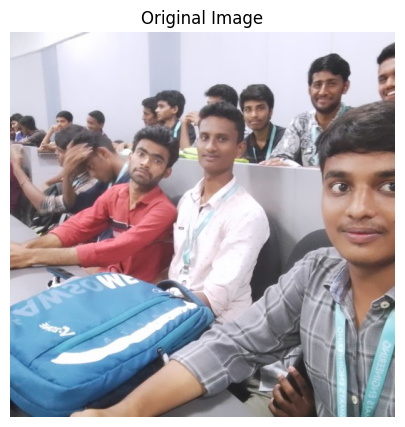

In [3]:
plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()

In [5]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94


In [6]:
!pip install opencv-contrib-python-headless

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.5/69.5 MB 44.4 MB/s  0:00:01


In [1]:
import cv2

print("OpenCV version:", cv2.__version__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

assert hasattr(cv2, "CascadeClassifier"), "OpenCV installation needs checking!"

print("OpenCV is working correctly!")

OpenCV version: 5.0.0
CascadeClassifier available: True
OpenCV is working correctly!


In [3]:
import urllib.request
import os

url = "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_eye.xml"

urllib.request.urlretrieve(url, "/content/haarcascade_eye.xml")

print("File downloaded:", os.path.exists("/content/haarcascade_eye.xml"))

File downloaded: True


In [4]:
import cv2

eye_cascade = cv2.CascadeClassifier("/content/haarcascade_eye.xml")

if eye_cascade.empty():
    raise RuntimeError("Eye classifier could not be loaded.")

print("Eye classifier loaded successfully!")

Eye classifier loaded successfully!


In [11]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

image = cv2.imread(filename)

if image is None:
    raise ValueError("Image could not be loaded. Please upload a valid image.")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("Image loaded successfully!")
print("Grayscale conversion completed!")

Saving 1000003468.jpg to 1000003468.jpg
Image loaded successfully!
Grayscale conversion completed!


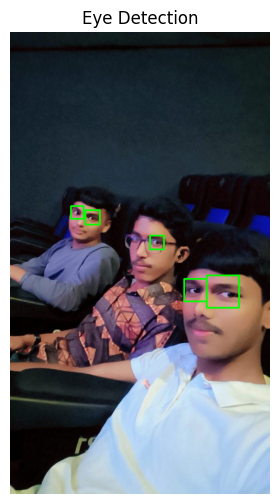

Number of eyes detected: 5


In [12]:
eyes = eye_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(20, 20)
)

eye_image = image.copy()

for (x, y, w, h) in eyes:
    cv2.rectangle(eye_image, (x, y), (x+w, y+h), (0, 255, 0), 2)

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(eye_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Eye Detection")
plt.show()

print("Number of eyes detected:", len(eyes))